# Chapter 22: Project: Customer Survey

The programs from Chapter 22 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Net Promoter Score

`survey_nps.py`

In [1]:
import pandas as pd

survey = pd.read_csv("../data/survey.csv", keep_default_na=False)

survey["group"] = pd.cut(
    survey["recommend"],
    bins=[-1, 6, 8, 10],
    labels=["detractor", "passive", "promoter"],
)
shares = pd.crosstab(survey["plan"], survey["group"], normalize="index")
shares["NPS"] = 100 * (shares["promoter"] - shares["detractor"])
print(shares.round(2).reindex(["Basic", "Plus", "Pro"]))
print()
overall = survey["group"].value_counts(normalize=True)
print(
    f"overall NPS: {100 * (overall['promoter'] - overall['detractor']):.0f}"
)
print(survey.groupby("plan")["satisfaction"].mean().round(2).to_string())

group  detractor  passive  promoter    NPS
plan                                      
Basic       0.51     0.32      0.18 -33.08
Plus        0.32     0.38      0.31  -1.26
Pro         0.21     0.37      0.42  21.43

overall NPS: -12
plan
Basic    3.22
Plus     3.71
Pro      4.02


## What the Comments Say

`survey_comments.py`

In [2]:
import pandas as pd

survey = pd.read_csv("../data/survey.csv", keep_default_na=False)
themes = {
    "speed": r"slow|fast",
    "price": r"price|value",
    "support": r"support",
    "ease of use": r"easy|confusing",
}
low = survey[survey["satisfaction"] <= 2]
high = survey[survey["satisfaction"] >= 4]

rows = []
for theme, pattern in themes.items():
    rows.append(
        {
            "theme": theme,
            "unhappy (1-2)": low["comment"].str.contains(pattern).mean(),
            "happy (4-5)": high["comment"].str.contains(pattern).mean(),
        }
    )
print(pd.DataFrame(rows).set_index("theme").round(2))
print()
print("blank comments:", (survey["comment"] == "").sum())

             unhappy (1-2)  happy (4-5)
theme                                  
speed                 0.55         0.25
price                 0.21         0.28
support               0.21         0.22
ease of use           0.23         0.24

blank comments: 31


## The Chart

`survey_chart.py`

Saved survey_chart.png


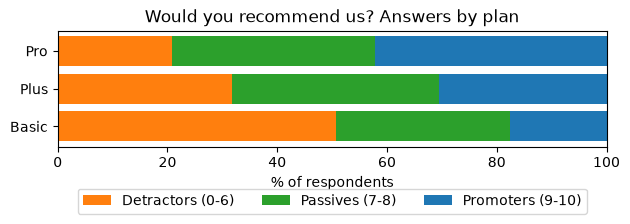

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

survey = pd.read_csv("../data/survey.csv")
survey["group"] = pd.cut(
    survey["recommend"],
    bins=[-1, 6, 8, 10],
    labels=["Detractors (0-6)", "Passives (7-8)", "Promoters (9-10)"],
)
shares = (
    pd.crosstab(survey["plan"], survey["group"], normalize="index").reindex(
        ["Basic", "Plus", "Pro"]
    )
    * 100
)

fig, ax = plt.subplots(figsize=(6.4, 2.6))
left = pd.Series(0.0, index=shares.index)
for group, color in zip(shares.columns, ["C1", "C2", "C0"]):
    ax.barh(
        shares.index, shares[group], left=left, color=color, label=group
    )
    left += shares[group]
ax.set_xlim(0, 100)
ax.set_xlabel("% of respondents")
ax.set_title("Would you recommend us? Answers by plan")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3))
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("survey_chart.png")
print("Saved survey_chart.png")